# Entrega 1: Classificação de histórico de AVC (Brain Stroke)


**Dupla:** Joaquim Veras e Luiz Henrique Falcão


Estrutura:
1. O problema e os dados
2. Exploração
3. Preparação
4. Baselines com busca de hiperparâmetros (árvore e kNN)
5. Resultado e diagnóstico
6. Declaração de uso de IA
7. Bônus: LVQ como terceiro baseline

## Imports e Seed

In [ ]:
import numpy as np                                    # arrays
import pandas as pd                                   # tabelas
import math
import random
import matplotlib.pyplot as plt                       # gráficos
from google.colab import drive                        # csv
from IPython.display import display

from sklearn.model_selection import train_test_split  # divisão
from sklearn.preprocessing import StandardScaler, OneHotEncoder      # padronização
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
)


SEMENTE = 10  # reprodutibilidade

drive.mount("/content/drive")
caminho_csv = "/content/drive/MyDrive/aprendizado_de_maquina_1/brain_stroke.csv"
dados = pd.read_csv(caminho_csv)

print("Formato:", dados.shape)
dados.head()

# Cores dos graficos
VERM, CINZA, AZUL = "#C8102E", "#333333", "#1f4e79"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Formato: (4981, 11)


## Seção 1: O problema e os dados


### A pergunta

**É possível identificar, a partir de atributos clínicos e demográficos simples, se um registro pertence a um paciente com histórico de AVC?**

### A fonte

- **Dataset:** Brain Stroke Dataset
- **Publicador:** Jillani SofTech
- **Origem:** [Kaggle — Brain Stroke Dataset](https://www.kaggle.com/datasets/jillanisofttech/brain-stroke-dataset)
- **Versão:** versão 1, publicada em 4 de agosto de 2022
- **Data de acesso:** 16 de setembro de 2026
- **Licença:** Open Database License para a base de dados e Database Contents License para seu conteúdo
- **Formato:** arquivo CSV com 4.981 registros, 10 atributos preditores e 1 alvo


### Os atributos

| Atributo | Tipo | Significado |
|---|---|---|
| `gender` | categórico binário | Sexo registrado do paciente (`Male` ou `Female`) |
| `age` | numérico contínuo | Idade do paciente em anos |
| `hypertension` | binário | 1 se possui hipertensão; 0 caso contrário |
| `heart_disease` | binário | 1 se possui doença cardíaca; 0 caso contrário |
| `ever_married` | categórico binário | Indica se o paciente já foi casado (`Yes` ou `No`) |
| `work_type` | categórico nominal | Tipo de trabalho (`Private`, `Self-employed`, `Govt_job` ou `children`) |
| `Residence_type` | categórico binário | Tipo de residência (`Urban` ou `Rural`) |
| `avg_glucose_level` | numérico contínuo | Nível médio de glicose no sangue |
| `bmi` | numérico contínuo | Índice de massa corporal |
| `smoking_status` | categórico nominal | Situação de tabagismo (`never smoked`, `formerly smoked`, `smokes` ou `Unknown`) |
| **`stroke`** | **alvo binário** | **1 se o paciente teve AVC; 0 caso contrário** |

A categoria `Unknown` de `smoking_status` indica que a informação sobre tabagismo não está disponível para aquele paciente.

### O alvo

`stroke` é um alvo de classificação binária:

- `0`: paciente sem histórico de AVC;
- `1`: paciente com histórico de AVC.

A classe positiva (`stroke = 1`) é a de maior interesse. Como ela representa apenas aproximadamente 5% dos registros, o desbalanceamento das classes deverá ser considerado na preparação, na escolha das métricas e na avaliação dos modelos.

## Seção 2: Exploração

### 2.1 Dimensões, tipos e valores faltantes

In [ ]:
print("Registros:", dados.shape[0])  # linhas
print("Colunas:", dados.shape[1])    # colunas

print("\nTipos:")  # título
display(dados.dtypes.rename("tipo").to_frame())  # tipos

qualidade = pd.DataFrame({  # tabela
    "faltantes_NaN": dados.isna().sum(),              # ausências
    "valores_unicos": dados.nunique(dropna=False),    # variedade
})
display(qualidade)  # exibição

print("Linhas totalmente duplicadas:", dados.duplicated().sum())  # duplicatas

print(
    "Valores infinitos nas colunas numéricas:",  # descrição
    int(np.isinf(dados.select_dtypes(include=np.number)).sum().sum()),  # infinitos
)

print(
    "Registros com smoking_status = Unknown:",  # descrição
    (dados["smoking_status"] == "Unknown").sum(),  # quantidade
    f"({(dados['smoking_status'] == 'Unknown').mean():.1%})",  # percentual
)

print("\nResumo dos contínuos:")  # título
display(
    dados[["age", "avg_glucose_level", "bmi"]].describe().T
)  # estatísticas

print("\nCategorias observadas:")  # título

for coluna in [  # percorre colunas
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status",
]:
    print(
        f"{coluna}: {sorted(dados[coluna].unique().tolist())}"
    )  # categorias

Registros: 4981
Colunas: 11

Tipos:


,tipo
gender,object
age,float64
hypertension,int64
heart_disease,int64
ever_married,object
work_type,object
Residence_type,object
avg_glucose_level,float64
bmi,float64
smoking_status,object


,faltantes_NaN,valores_unicos
gender,0,2
age,0,104
hypertension,0,2
heart_disease,0,2
ever_married,0,2
work_type,0,4
Residence_type,0,2
avg_glucose_level,0,3895
bmi,0,342
smoking_status,0,4


Linhas totalmente duplicadas: 0
Valores infinitos nas colunas numéricas: 0
Registros com smoking_status = Unknown: 1500 (30.1%)

Resumo dos contínuos:


,count,mean,std,min,25%,50%,75%,max
age,4981.0,43.419859,22.662755,0.08,25.00,45.00,61.00,82.00
avg_glucose_level,4981.0,105.943562,45.075373,55.12,77.23,91.85,113.86,271.74
bmi,4981.0,28.498173,6.790464,14.00,23.70,28.10,32.60,48.90



Categorias observadas:
gender: ['Female', 'Male']
ever_married: ['No', 'Yes']
work_type: ['Govt_job', 'Private', 'Self-employed', 'children']
Residence_type: ['Rural', 'Urban']
smoking_status: ['Unknown', 'formerly smoked', 'never smoked', 'smokes']


**Interpretação:** Não foram encontrados valores `NaN`, infinitos ou registros duplicados. Entretanto, `Unknown` em `smoking_status` representa uma ausência semântica de informação e aparece em aproximadamente 30% dos registros. Essa categoria será mantida explicitamente, pois pode conter informação relevante e não há justificativa para atribuir outro hábito de tabagismo a esses pacientes. Valores elevados de glicose e IMC também não serão removidos automaticamente, pois permanecem em intervalos plausíveis e podem representar casos clinicamente relevantes, e não erros de medição.

### 2.2 Balanceamento do alvo

,quantidade,proporção
stroke,,
0,4733,0.950211
1,248,0.049789


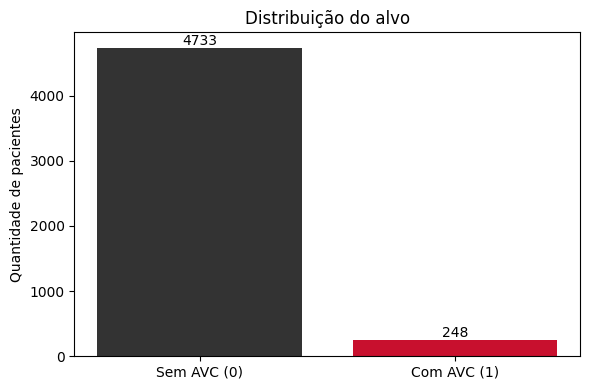

In [ ]:
contagem = dados["stroke"].value_counts().sort_index()  # quantidades
proporcao = dados["stroke"].value_counts(
    normalize=True
).sort_index()  # proporções

display(
    pd.DataFrame({
        "quantidade": contagem,  # valores absolutos
        "proporção": proporcao,  # valores relativos
    })
)  # exibição

plt.figure(figsize=(6, 4))  # tamanho

barras = plt.bar(  # gráfico
    ["Sem AVC (0)", "Com AVC (1)"],  # classes
    [contagem.get(0, 0), contagem.get(1, 0)],  # alturas
    color=[CINZA, VERM],  # cores
)

plt.bar_label(barras)                  # rótulos
plt.ylabel("Quantidade de pacientes")  # eixo vertical
plt.title("Distribuição do alvo")      # título
plt.tight_layout()                     # ajusta margens
plt.show()                             # exibição

**Interpretação:** A base é fortemente desbalanceada: 4.733 registros (aproximadamente 95%) pertencem à classe sem AVC, enquanto apenas 248 (aproximadamente 5%) pertencem à classe com AVC. Um classificador que sempre previsse a classe 0 alcançaria cerca de 95% de acurácia, mesmo sem identificar nenhum caso de AVC. Por isso, a acurácia simples não será analisada isoladamente. A métrica principal para comparar e selecionar os modelos será a **acurácia balanceada**, que corresponde à média entre o recall da classe com AVC e o recall da classe sem AVC, também chamado de especificidade.

### 2.3 Distribuição dos atributos numéricos por classe

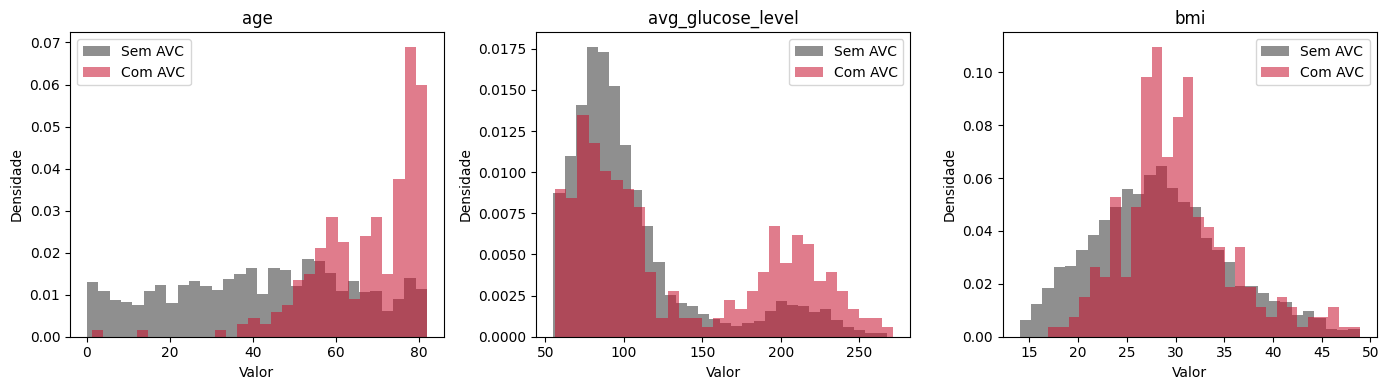

age                      avg_glucose_level                         \
       count   mean median    std             count    mean  median    std   
stroke                                                                       
0       4733  42.14   43.0  22.35              4733  104.57   91.45  43.60   
1        248  67.82   71.0  12.67               248  132.18  105.04  61.77   

         bmi                      
       count   mean median   std  
stroke                            
0       4733  28.41  28.00  6.83  
1        248  30.19  29.45  5.66

In [ ]:
continuos_eda = [  # contínuos
    "age",
    "avg_glucose_level",
    "bmi",
]

fig, eixos = plt.subplots(
    1, 3, figsize=(14, 4)
)  # cria gráficos

for eixo, coluna in zip(eixos, continuos_eda):  # percorre atributos

    for classe, cor, nome in [  # percorre classes
        (0, CINZA, "Sem AVC"),
        (1, VERM, "Com AVC"),
    ]:
        eixo.hist(  # histograma
            dados.loc[dados["stroke"] == classe, coluna],  # filtra classe
            bins=30,       # intervalos
            density=True,  # normaliza
            alpha=0.55,    # transparência
            color=cor,     # cor
            label=nome,    # legenda
        )

    eixo.set_title(coluna)       # título
    eixo.set_xlabel("Valor")     # eixo horizontal
    eixo.set_ylabel("Densidade") # eixo vertical
    eixo.legend()                # legenda

plt.tight_layout()  # ajusta margens
plt.show()          # exibição

resumo_classes = dados.groupby("stroke")[continuos_eda].agg(
    ["count", "mean", "median", "std"]
)  # estatísticas por classe

display(resumo_classes.round(2))  # exibição

**Interpretação:** A **idade** apresenta a diferença mais acentuada entre as classes: pacientes com AVC possuem média de 67,82 anos e mediana de 71 anos, enquanto pacientes sem AVC possuem média de 42,14 anos e mediana de 43 anos. A **glicose média** também é mais elevada entre os pacientes com AVC, embora sua grande dispersão indique sobreposição entre as classes. O **IMC (`bmi`)** apresenta uma diferença menor, com médias de 30,19 na classe com AVC e 28,41 na classe sem AVC. Assim, idade e glicose parecem mais promissoras para a classificação, enquanto o IMC possui menor capacidade de separação quando analisado isoladamente. Essas relações são descritivas e não demonstram causalidade.

### 2.4 Relação dos atributos categóricos e binários com o alvo


In [ ]:
categoricos_eda = [  # categóricos
    "hypertension",
    "heart_disease",
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status",
]

tabelas = []  # resultados

for coluna in categoricos_eda:  # percorre atributos

    tabela = (  # resumo
        dados.groupby(
            coluna,
            dropna=False,
        )["stroke"]  # agrupa categorias
        .agg(
            total="size",       # registros
            casos_AVC="sum",    # casos positivos
            taxa_AVC="mean",    # proporção positiva
        )
        .reset_index()           # transforma índice
    )

    tabela.insert(
        0,
        "atributo",
        coluna,
    )  # identifica atributo

    tabelas.append(
        tabela.rename(columns={coluna: "categoria"})
    )  # armazena tabela

relacoes_categoricas = pd.concat(
    tabelas,
    ignore_index=True,
)  # combina tabelas

relacoes_categoricas["taxa_AVC"] = (
    relacoes_categoricas["taxa_AVC"].round(4)
)  # arredonda taxa

display(relacoes_categoricas)  # exibição

,atributo,categoria,total,casos_AVC,taxa_AVC
0,hypertension,0,4502,182,0.0404
1,hypertension,1,479,66,0.1378
2,heart_disease,0,4706,201,0.0427
3,heart_disease,1,275,47,0.1709
4,gender,Female,2907,140,0.0482
5,gender,Male,2074,108,0.0521
6,ever_married,No,1701,29,0.0170
7,ever_married,Yes,3280,219,0.0668
8,work_type,Govt_job,644,33,0.0512
9,work_type,Private,2860,148,0.0517


### Análise

A taxa média de AVC no dataset é de aproximadamente **5%**. Algumas categorias apresentam taxas consideravelmente superiores:

- **Hipertensão:** pacientes hipertensos apresentam taxa de AVC de **13,78%**, contra **4,04%** entre os não hipertensos.
- **Doença cardíaca:** pacientes com essa condição apresentam taxa de **17,09%**, contra **4,27%** entre os demais.
- **Estado civil e trabalho:** pacientes que já foram casados e trabalhadores autônomos apresentam taxas maiores. Entretanto, essas relações podem estar associadas à **idade**, pois esses grupos tendem a conter pacientes mais velhos.
- **Sexo e residência:** apresentam diferenças pequenas entre as categorias, indicando menor capacidade de separação quando analisados isoladamente.
- **Tabagismo:** ex-fumantes apresentam a maior taxa de AVC (**8,07%**). Entretanto, essa relação também pode sofrer influência da idade. A categoria `Unknown` representa uma ausência semântica de informação.

**Resumo da exploração:** os atributos aparentemente mais promissores são **idade, hipertensão, doença cardíaca e glicose**. O principal desafio é o forte **desbalanceamento do alvo**, pois apenas cerca de 5% dos registros pertencem à classe com AVC. Essas relações são descritivas e não demonstram causalidade.

## Seção 3: Preparação

Três passos: codificar os categóricos, dividir em treino / validação / teste, e padronizar os numéricos.

### 3.1 Divisão em treino, validação e teste

In [ ]:
X_bruto = dados.drop(columns=["stroke"])  # atributos
y = dados["stroke"]                       # alvo

# Reserva 20% para teste
X_tmp, X_te, y_tmp, y_te = train_test_split(
    X_bruto,             # atributos
    y,                   # alvo
    test_size=0.20,      # 20% teste
    random_state=SEMENTE, # reprodutibilidade
    stratify=y,          # preserva proporções
)

# Reserva 20% para validação
X_tr, X_va, y_tr, y_va = train_test_split(
    X_tmp,               # dados restantes
    y_tmp,               # alvos restantes
    test_size=0.25,      # 25% dos 80%
    random_state=SEMENTE, # reprodutibilidade
    stratify=y_tmp,      # preserva proporções
)

particoes = pd.DataFrame([  # tabela resumo
    {
        "conjunto": "Treino",                    # nome
        "registros": len(X_tr),                  # quantidade
        "casos_AVC": int(y_tr.sum()),            # casos positivos
        "proporção_AVC": f"{y_tr.mean():.1%}",   # percentual
    },
    {
        "conjunto": "Validação",                 # nome
        "registros": len(X_va),                  # quantidade
        "casos_AVC": int(y_va.sum()),            # casos positivos
        "proporção_AVC": f"{y_va.mean():.1%}",   # percentual
    },
    {
        "conjunto": "Teste (fechado)",           # nome
        "registros": len(X_te),                  # quantidade
        "casos_AVC": "não consultado",           # teste fechado
        "proporção_AVC": "não consultada",       # teste fechado
    },
])

display(particoes)  # exibição

,conjunto,registros,casos_AVC,proporção_AVC
0,Treino,2988,148,5.0%
1,Validação,996,50,5.0%
2,Teste (fechado),997,não consultado,não consultada


Interpretação: Os dados foram divididos em 60% para treino, 20% para validação e 20% para teste, utilizando uma semente fixa para garantir a reprodução dos resultados. A estratificação preserva a proporção de casos de AVC em cada conjunto. O treino será usado para ajustar os modelos, a validação para escolher os melhores hiperparâmetros e o teste permanecerá fechado até a avaliação final na Seção 5.

### 3.2 Codificação e padronização de numéricos contínuos

In [ ]:
continuos = [  # contínuos
    "age",
    "avg_glucose_level",
    "bmi",
]

binarios_numericos = [  # binários numéricos
    "hypertension",
    "heart_disease",
]

categoricos = [  # categóricos
    "gender",
    "ever_married",
    "Residence_type",
    "work_type",
    "smoking_status",
]

preprocessador = ColumnTransformer(
    transformers=[
        (
            "continuos",          # nome
            StandardScaler(),     # padronização
            continuos,            # colunas
        ),
        (
            "binarios",           # nome
            "passthrough",        # mantém valores
            binarios_numericos,   # colunas
        ),
        (
            "categoricos",        # nome
            OneHotEncoder(
                drop="if_binary",          # remove redundância binária
                handle_unknown="ignore",   # aceita categorias novas
                sparse_output=False,       # matriz densa
            ),
            categoricos,          # colunas
        ),
    ],
    verbose_feature_names_out=False,  # nomes simples
)

X_tr_s = preprocessador.fit_transform(
    X_tr
)  # aprende e transforma

X_va_s = preprocessador.transform(
    X_va
)  # transforma validação

y_tr_a = np.asarray(y_tr)  # converte alvo
y_va_a = np.asarray(y_va)  # converte alvo

nomes_atributos = (
    preprocessador.get_feature_names_out()
)  # nomes finais

print(
    "Formato do treino preparado:",
    X_tr_s.shape,
)  # dimensões

print("Atributos finais:")  # título
print(nomes_atributos)      # atributos

Formato do treino preparado: (2988, 16)
Atributos finais:
['age' 'avg_glucose_level' 'bmi' 'hypertension' 'heart_disease'
 'gender_Male' 'ever_married_Yes' 'Residence_type_Urban'
 'work_type_Govt_job' 'work_type_Private' 'work_type_Self-employed'
 'work_type_children' 'smoking_status_Unknown'
 'smoking_status_formerly smoked' 'smoking_status_never smoked'
 'smoking_status_smokes']


Interpretação: Os atributos contínuos foram padronizados com parâmetros aprendidos exclusivamente no treino. Os atributos binários numéricos foram mantidos em 0/1, enquanto os categóricos foram codificados por one-hot. A mesma transformação foi aplicada à validação, sem reajuste, e o teste permaneceu fechado até a avaliação final.

## Seção 4: Baselines com busca de hiperparâmetros

### Seção 4.1: KNN

In [ ]:
class instancia:
    def __init__(
        self,
        atributos: np.ndarray,
        rotulo: str,
    ):
        self.atributos = atributos  # guarda atributos
        self.rotulo = rotulo        # guarda classe

        pass  # encerra método

    def _distancia(
        self,
        ponto_y: np.ndarray,
    ) -> float:
        saida = 0  # inicia distância

        for i, j in zip(
            self.atributos,
            ponto_y,
        ):  # percorre atributos
            saida += (i - j) ** 2  # soma diferenças

        return saida ** 0.5  # raiz quadrada


class knn:
    def __init__(
        self,
        base_treino: np.ndarray[np.ndarray[float]],
        rotulos: np.ndarray[str],
        k_defalt=3,
    ):
        base_treino = np.array(base_treino)  # converte atributos
        rotulos = np.array(rotulos)          # converte rótulos

        self.treino = [
            instancia(i, j)
            for i, j in zip(base_treino, rotulos)
        ]  # cria instâncias

        self.k = k_defalt  # guarda vizinhos

        pass  # encerra método

    def predicit(
        self,
        objetivo: np.ndarray,
        k=-1,
    ) -> str:
        objetivo = np.array(objetivo)  # converte exemplo

        if k == -1:
            k = self.k  # usa padrão

        resultado = [
            10**10 for x in range(k)
        ]  # inicia distâncias

        label = [
            0 for x in range(k)
        ]  # inicia classes

        for i in self.treino:  # percorre treino
            distancia = i._distancia(
                objetivo
            )  # calcula distância

            for j in range(
                len(resultado)
            ):  # procura posição
                if distancia < resultado[j]:
                    resultado.insert(j,distancia)  # guarda distância
                    label.insert(j,i.rotulo)        # guarda classe
                    resultado.pop()
                    label.pop()
                    break                     # encerra busca

        saida = (
            label[0],
            label.count(label[0]),
        )  # inicia votação

        for i in range(
            1,
            len(label),
        ):  # percorre classes
            if label.count(label[i]) > saida[1]:
                saida = (
                    label[i],
                    label.count(label[i]),
                )  # atualiza maioria

        return saida[0]  # retorna classe

    def acuracia(
        self,
        testes: np.ndarray[np.ndarray[float]],
        rotulos: np.ndarray[str],
    ) -> float:
        testes = np.array(testes)    # converte testes
        rotulos = np.array(rotulos)  # converte rótulos
        acertos = 0                  # inicia contador

        for i, j in zip(
            testes,
            rotulos,
        ):  # percorre exemplos
            if self.predicit(i) == j:
                acertos += 1  # contabiliza acerto

        return acertos / len(testes)  # calcula acurácia

### Seção 4.2: ARVORE

In [ ]:
class arvore:
    def __init__(
        self,
        dados,
        rotulos,
        max_dept=5,
        dept=0,
        minsample=1,
    ):
        self.min = minsample          # mínimo de amostras
        self.dados = dados            # guarda dados
        self.rotulos = rotulos        # guarda classes
        self.dados["rotulos"] = rotulos  # adiciona classes
        self.tamanho = len(rotulos)   # tamanho do nó
        self.entropi_rotulo = self.entropia_raiz()  # entropia atual
        self.max_dept = max_dept      # profundidade máxima
        self.dept = dept              # profundidade atual

        maior_ganho = (0, 0)  # melhor divisão

        for i in self.dados:  # percorre atributos
            if i != "rotulos":  # ignora alvo
                x = self.entropia(i)  # entropia resultante

                if self.entropi_rotulo - x > maior_ganho[1]:
                    maior_ganho = (
                        i,
                        self.entropi_rotulo - x,
                    )  # atualiza ganho

        filhos_possiveis = []  # valores do atributo

        if maior_ganho[1] > 0:
            filhos_possiveis = np.unique(
                self.dados[maior_ganho[0]]
            )  # encontra valores

        self.filhos_nomes = []  # identifica ramos

        if (
            dept < max_dept
            and maior_ganho[1] > 0
            and len(rotulos) >= minsample
        ):  # verifica divisão
            self.filhos = []  # armazena filhos

            for i in filhos_possiveis:  # cria ramos
                filtro = (
                    dados[maior_ganho[0]] == i
                )  # seleciona categoria

                self.filhos.append(
                    arvore(
                        dados[filtro],
                        self.dados[filtro]["rotulos"],
                        max_dept,
                        dept + 1,
                        self.min,
                    )
                )  # cria subárvore

                self.filhos_nomes.append(
                    i
                )  # registra categoria

            self.escolha = maior_ganho[0]  # atributo escolhido

        else:
            x, y = np.unique(
                np.array(rotulos),
                return_counts=True,
            )  # conta classes

            self.escolha = (0, 0)  # inicia maioria

            for i, j in zip(x, y):  # percorre classes
                if j > self.escolha[1]:
                    self.escolha = (
                        i,
                        j,
                    )  # atualiza maioria

            self.escolha = self.escolha[0]  # guarda classe

        pass  # encerra método

    def entropia_fundo(
        self,
        exemplo,
        x,
    ):
        saida = []        # contagens por classe
        saida_final = 0   # entropia acumulada

        for i in np.unique(
            self.rotulos
        ):  # percorre classes
            quantidade = np.size(
                self.dados[
                    (self.dados[x] == exemplo)
                    & (self.dados["rotulos"] == i)
                ][x]
            )  # conta ocorrências

            saida.append(
                quantidade
            )  # guarda contagem

        total = np.sum(saida)  # total do grupo

        for j in saida:  # percorre contagens
            saida_final -= (
                (j / total) * math.log(j / total, 2)
                if j > 0
                else 0
            )  # calcula entropia

        return saida_final  # retorna entropia

    def entropia(
        self,
        x,
    ):
        valores_unicos, valores_count = np.unique(
            self.dados[x],
            return_counts=True,
        )  # valores e frequências

        saida = 0  # entropia ponderada

        for i, j in zip(
            valores_unicos,
            valores_count,
        ):  # percorre valores
            saida += (
                self.entropia_fundo(i, x)
                * j
                / self.tamanho
            )  # pondera entropia

        return saida  # retorna resultado

    def entropia_raiz(self):
        diferentes, n = np.unique(
            self.rotulos,
            return_counts=True,
        )  # conta classes

        total = len(self.rotulos)  # total de exemplos

        return np.sum(
            [
                x / total
                * -1
                * math.log(x / total, 2)
                for x in n
            ]
        )  # calcula entropia

    def predcit(
        self,
        x,
    ):
        if (
            self.dept < self.max_dept
            and len(self.filhos_nomes) > 0
            and len(self.rotulos) >= self.min
        ):  # verifica ramificação
            try:
                indice = self.filhos_nomes.index(
                    x[self.escolha]
                )  # encontra ramo

                return self.filhos[
                    indice
                ].predcit(x)  # continua descida

            except:
                x, y = np.unique(
                    np.array(self.rotulos),
                    return_counts=True,
                )  # conta classes

                escolha = (0, 0)  # inicia maioria

                for i, j in zip(x, y):  # percorre classes
                    if j > escolha[1]:
                        escolha = (
                            i,
                            j,
                        )  # atualiza maioria

                escolha = escolha[0]  # guarda classe
                return escolha        # retorna maioria

        return self.escolha  # retorna previsão

    def acuracia(
        self,
        x,
        y,
    ):
        resultado = 0  # inicia acertos

        for i, j in zip(
            range(len(x)),
            y,
        ):  # percorre exemplos
            if self.predcit(x.iloc[i]) == j:
                resultado += 1  # contabiliza acerto

        return resultado / len(y)  # calcula acurácia

In [ ]:
class sql:
    def __init__(
        self,
        base_treino: np.ndarray[np.ndarray[float]],
        rotulos: np.ndarray[str],
        quantidade_nodes_porclasse=1,
    ):
        base_treino = np.array(
            base_treino
        )  # converte atributos

        rotulos = np.array(
            rotulos
        )  # converte rótulos

        self.total_elementos = len(
            rotulos
        )  # quantidade de exemplos

        self.treino = [
            instancia(atributos, rotulo)
            for atributos, rotulo in zip(
                base_treino,
                rotulos,
            )
        ]  # cria instâncias

        self.totalnodes = (
            quantidade_nodes_porclasse
        )  # protótipos por classe

        self.criar_nodes(
            rotulos
        )  # cria protótipos

        pass  # encerra método

    def _predicit(
        self,
        objetivo: np.ndarray,
    ) -> str:
        objetivo = np.array(
            objetivo
        )  # converte exemplo

        saida = (
            0,
            None,
        )  # melhor protótipo

        for i in self.nodes:  # percorre protótipos
            quase_distancia = i._distancia(
                objetivo
            )  # calcula distância

            if (
                saida[1] is None
                or quase_distancia < saida[1]
            ):  # verifica proximidade
                saida = (
                    i,
                    quase_distancia,
                )  # atualiza vencedor

        return saida[0]  # retorna protótipo

    def criar_nodes(
        self,
        rotulos,
    ):
        self.nodes = []  # inicia protótipos

        for j in np.unique(
            rotulos
        ):  # percorre classes
            for i in range(
                self.totalnodes
            ):  # cria por classe
                atributos_aleatorios = [
                    random.randint(0, 1)
                    for i in range(
                        self.total_elementos
                    )
                ]  # gera atributos

                self.nodes.append(
                    instancia(
                        atributos_aleatorios,
                        j,
                    )
                )  # adiciona protótipo

        pass  # encerra método

    def acuracia(
        self,
        testes: np.ndarray[np.ndarray[float]],
        rotulos: np.ndarray[str],
    ) -> float:
        testes = np.array(
            testes
        )  # converte testes

        rotulos = np.array(
            rotulos
        )  # converte rótulos

        acertos = 0  # inicia contador

        for i, j in zip(
            testes,
            rotulos,
        ):  # percorre exemplos
            if self.predicit(i) == j:
                acertos += 1  # contabiliza acerto

        return (
            acertos / len(testes)
        )  # calcula acurácia

    def atualizar(
        self,
        node,
        elemento,
        alfa,
    ):
        x = (
            True
            if node.rotulo == elemento.rotulo
            else False
        )  # compara classes

        for i, j in zip(
            node.atributos,
            elemento.atributos,
        ):  # percorre atributos
            if x:  # mesma classe
                i += (
                    alfa
                    * (i - j)
                    * (1 if x else -1)
                )  # tenta atualizar

    def treinar(
        self,
        alfa=0.01,
    ):
        for i in self.treino:  # percorre treino
            vencedor = self._predicit(
                i.atributos
            )  # encontra protótipo

            self.atualizar(
                vencedor,
                i,
                alfa,
            )  # atualiza protótipo

    def predicit(
        self,
        objetivo,
    ):
        return self._predicit(
            objetivo
        ).rotulo  # retorna classe

### Seção 4.3: teste knn

0.02
melho k achado
melhor k é 20 com acuracia de 0.9497991967871486


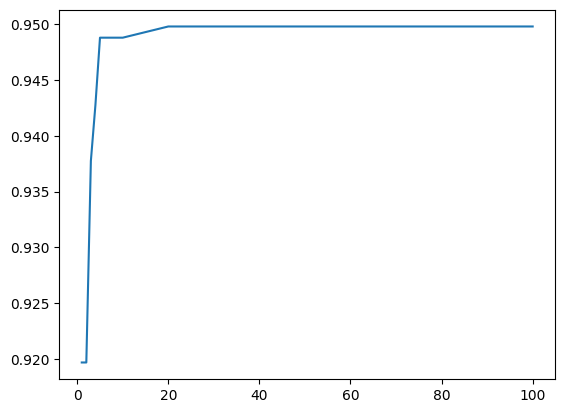

o knn acertou 0.0% dos casos positivos
melho k achado
melhor k é 1 com precisão de 0.08


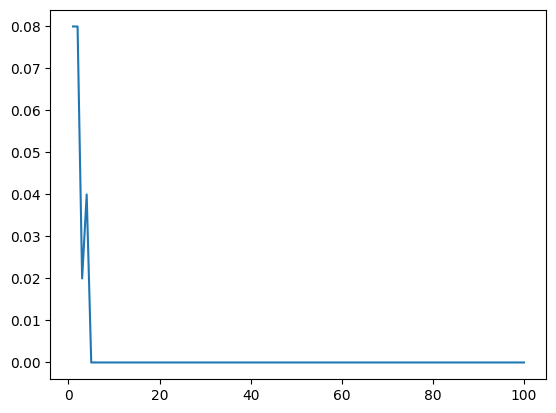

In [ ]:
# Converte treino para DataFrame
x_tr_s_pd = pd.DataFrame(
    X_tr_s,
    columns=nomes_atributos,
)

# Cria kNN inicial
meu_teste = knn(
    X_tr_s,
    y_tr,
)

# Avalia somente positivos
resultado_inicial = meu_teste.acuracia(
    X_va_s[y_va == 1],
    y_va[y_va == 1],
)

print(
    resultado_inicial
)

# Primeira busca: acurácia geral
total = []           # guarda acurácias
total2 = []          # guarda valores k
fig, ax = plt.subplots()  # cria gráfico
melhork = (0, 0)     # melhor resultado

for k in [
    1, 2, 3, 4, 5,
    10, 20, 25, 100,
]:
    teste = knn(
        X_tr_s,
        y_tr,
        k_defalt=k,
    ).acuracia(
        X_va_s,
        y_va,
    )  # avalia validação

    total.append(
        teste
    )  # guarda acurácia

    total2.append(
        k
    )  # guarda k

    if teste > melhork[1]:
        melhork = (
            k,
            teste,
        )  # atualiza vencedor

print(
    "melho k achado"
)

print(
    f"melhor k é {melhork[0]} "
    f"com acuracia de {melhork[1]}"
)

ax.plot(
    total2,
    total,
)  # plota resultados

plt.show()  # exibe gráfico

# Avalia positivos com vencedor
resultado = knn(
    X_tr_s,
    y_tr,
    melhork[0],
).acuracia(
    X_va_s[y_va == 1],
    y_va[y_va == 1],
)

print(
    f"o knn acertou {resultado}% "
    "dos casos positivos"
)

# Segunda busca: somente positivos
melhork = (0, 0)     # reinicia vencedor
total = []           # reinicia acurácias
total2 = []          # reinicia valores k
fig, ax = plt.subplots()  # cria gráfico

for k in [
    1, 2, 3, 4, 5,
    10, 20, 25, 100,
]:
    teste = knn(
        X_tr_s,
        y_tr,
        k_defalt=k,
    ).acuracia(
        X_va_s[y_va == 1],
        y_va[y_va == 1],
    )  # avalia positivos

    total.append(
        teste
    )  # guarda acurácia

    total2.append(
        k
    )  # guarda k

    if teste > melhork[1]:
        melhork = (
            k,
            teste,
        )  # atualiza vencedor

print(
    "melho k achado"
)

print(
    f"melhor k é {melhork[0]} "
    f"com precisão de {melhork[1]}"
)

ax.plot(
    total2,
    total,
)  # plota resultados

plt.show()  # exibe gráfico

##SEÇÃO 4.4 Seleção Árvore

A saída de streaming foi truncada nas últimas 5000 linhas.
See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_va.loc[:, "new bmi"].iloc[i] = 2
/tmp/ipykernel_6727/1545130859.py:208: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org

0.9407630522088354
0.06
melho k achado
melhor k é 1 com acuracia de 0.9497991967871486
a precisao é 0.0
0.9236947791164659
melho k achado
melhor k é 10 com precisão de 0.12 min sample = 1


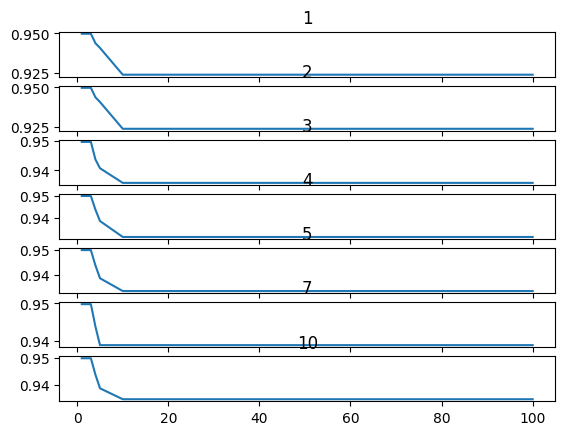

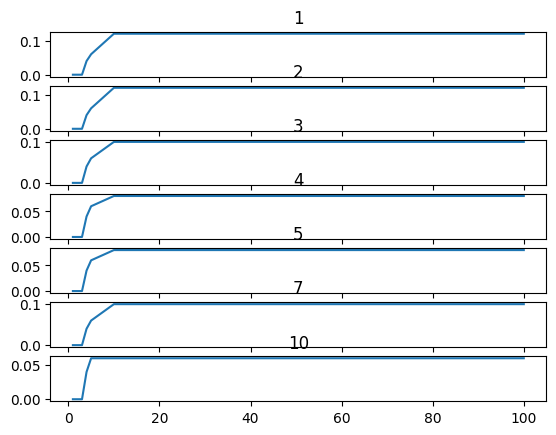

In [ ]:
# Analisa glicose
X_tr["avg_glucose_level"].describe()

# Exibe treino
X_tr

# Analisa BMI
X_tr["bmi"].describe()

# Analisa idade
X_tr["age"].describe()

# Exibe treino
X_tr


# ==========================================
# CATEGORIZAÇÃO DA IDADE
# ==========================================

# Copia idade do treino
X_tr["new_age"] = X_tr["age"]

for i in range(
    len(X_tr["new_age"])
):
    if X_tr["age"].iloc[i] < 18:
        X_tr.loc[:, "new_age"].iloc[i] = 0

    if (
        X_tr["age"].iloc[i] >= 18
        and X_tr["age"].iloc[i] < 30
    ):
        X_tr.loc[:, "new_age"].iloc[i] = 1

    if (
        X_tr["age"].iloc[i] >= 30
        and X_tr["age"].iloc[i] < 60
    ):
        X_tr.loc[:, "new_age"].iloc[i] = 2

    if X_tr["age"].iloc[i] >= 60:
        X_tr.loc[:, "new_age"].iloc[i] = 3


# Copia idade da validação
X_va["new_age"] = X_va["age"]

for i in range(
    len(X_va["new_age"])
):
    if X_va["age"].iloc[i] < 18:
        X_va.loc[:, "new_age"].iloc[i] = 0

    if (
        X_va["age"].iloc[i] >= 18
        and X_va["age"].iloc[i] < 30
    ):
        X_va.loc[:, "new_age"].iloc[i] = 1

    if (
        X_va["age"].iloc[i] >= 30
        and X_va["age"].iloc[i] < 60
    ):
        X_va.loc[:, "new_age"].iloc[i] = 2

    if X_va["age"].iloc[i] >= 60:
        X_va.loc[:, "new_age"].iloc[i] = 3


# Remove idade original
X_tr = X_tr.drop(
    "age",
    axis=1,
)

X_va = X_va.drop(
    "age",
    axis=1,
)

# X_te permanece inalterado


# ==========================================
# CATEGORIZAÇÃO DA GLICOSE
# ==========================================

# Copia glicose do treino
X_tr["new g"] = X_tr[
    "avg_glucose_level"
]

for i in range(
    len(X_tr["new g"])
):
    if X_tr["avg_glucose_level"].iloc[i] < 90:
        X_tr.loc[:, "new g"].iloc[i] = 0

    if (
        X_tr["avg_glucose_level"].iloc[i] >= 90
        and X_tr["avg_glucose_level"].iloc[i] < 110
    ):
        X_tr.loc[:, "new g"].iloc[i] = 1

    if (
        X_tr["avg_glucose_level"].iloc[i] >= 110
        and X_tr["avg_glucose_level"].iloc[i] < 150
    ):
        X_tr.loc[:, "new g"].iloc[i] = 2

    if X_tr["avg_glucose_level"].iloc[i] >= 150:
        X_tr.loc[:, "new g"].iloc[i] = 3


# Copia glicose da validação
X_va["new g"] = X_va[
    "avg_glucose_level"
]

for i in range(
    len(X_va["new g"])
):
    if X_va["avg_glucose_level"].iloc[i] < 90:
        X_va.loc[:, "new g"].iloc[i] = 0

    if (
        X_va["avg_glucose_level"].iloc[i] >= 90
        and X_va["avg_glucose_level"].iloc[i] < 110
    ):
        X_va.loc[:, "new g"].iloc[i] = 1

    if (
        X_va["avg_glucose_level"].iloc[i] >= 110
        and X_va["avg_glucose_level"].iloc[i] < 150
    ):
        X_va.loc[:, "new g"].iloc[i] = 2

    if X_va["avg_glucose_level"].iloc[i] >= 150:
        X_va.loc[:, "new g"].iloc[i] = 3


# Remove glicose original
X_tr = X_tr.drop(
    "avg_glucose_level",
    axis=1,
)

X_va = X_va.drop(
    "avg_glucose_level",
    axis=1,
)

# X_te permanece inalterado

# Exibe treino
X_tr


# ==========================================
# CATEGORIZAÇÃO DO BMI
# ==========================================

# Copia BMI do treino
X_tr["new bmi"] = X_tr["bmi"]

for i in range(
    len(X_tr["new bmi"])
):
    if X_tr["bmi"].iloc[i] < 25:
        X_tr.loc[:, "new bmi"].iloc[i] = 0

    if (
        X_tr["bmi"].iloc[i] >= 25
        and X_tr["bmi"].iloc[i] < 30
    ):
        X_tr.loc[:, "new bmi"].iloc[i] = 1

    if (
        X_tr["bmi"].iloc[i] >= 30
        and X_tr["bmi"].iloc[i] < 35
    ):
        X_tr.loc[:, "new bmi"].iloc[i] = 2

    if X_tr["bmi"].iloc[i] >= 35:
        X_tr.loc[:, "new bmi"].iloc[i] = 3


# Copia BMI da validação
X_va["new bmi"] = X_va["bmi"]

for i in range(
    len(X_va["new bmi"])
):
    if X_va["bmi"].iloc[i] < 25:
        X_va.loc[:, "new bmi"].iloc[i] = 0

    if (
        X_va["bmi"].iloc[i] >= 25
        and X_va["bmi"].iloc[i] < 30
    ):
        X_va.loc[:, "new bmi"].iloc[i] = 1

    if (
        X_va["bmi"].iloc[i] >= 30
        and X_va["bmi"].iloc[i] < 35
    ):
        X_va.loc[:, "new bmi"].iloc[i] = 2

    if X_va["bmi"].iloc[i] >= 35:
        X_va.loc[:, "new bmi"].iloc[i] = 3


# Remove BMI original
X_tr = X_tr.drop(
    "bmi",
    axis=1,
)

X_va = X_va.drop(
    "bmi",
    axis=1,
)

# X_te permanece inalterado


# ==========================================
# TESTE INICIAL DA ÁRVORE
# ==========================================

# Cria árvore inicial
teste_arvore = arvore(
    X_tr,
    y_tr,
)

# Avalia validação completa
print(
    teste_arvore.acuracia(
        X_va,
        y_va,
    )
)

# Avalia somente positivos
print(
    teste_arvore.acuracia(
        X_va[y_va == 1],
        y_va[y_va == 1],
    )
)


# ==========================================
# PRIMEIRA BUSCA DE HIPERPARÂMETROS
# ==========================================

# Melhor resultado
melhora = (0, 0)

# Cria gráficos
fig, ax = plt.subplots(
    7,
    1,
)

for j, z in zip(
    [1, 2, 3, 4, 5, 7, 10],
    [
        (0, 0),
        (1, 0),
        (2, 0),
        (3, 0),
        (4, 0),
        (5, 0),
        (6, 0),
    ],
):
    teste3 = []  # acurácias
    teste4 = []  # profundidades

    for k in [
        1, 2, 3, 4, 5,
        10, 20, 25, 100,
    ]:
        teste = arvore(
            X_tr,
            y_tr,
            max_dept=k,
            minsample=j,
        ).acuracia(
            X_va,
            y_va,
        )

        teste3.append(
            teste
        )

        teste4.append(
            k
        )

        if teste > melhora[1]:
            melhora = (
                k,
                teste,
            )

    ax[z[0]].plot(
        teste4,
        teste3,
    )

    ax[z[0]].set_title(
        j
    )

print(
    "melho k achado"
)

print(
    f"melhor k é {melhora[0]} "
    f"com acuracia de {melhora[1]}"
)

print(
    "a precisao é",
    arvore(
        X_tr,
        y_tr,
        max_dept=melhora[0],
    ).acuracia(
        X_va[y_va == 1],
        y_va[y_va == 1],
    ),
)


# ==========================================
# SEGUNDA BUSCA: SOMENTE POSITIVOS
# ==========================================

# Reinicia vencedor
melhora = (0, 0, 0)

# Cria gráficos
fig, ax = plt.subplots(
    7,
    1,
)

for j, z in zip(
    [1, 2, 3, 4, 5, 7, 10],
    [
        (0, 0),
        (1, 0),
        (2, 0),
        (3, 0),
        (4, 0),
        (5, 0),
        (6, 0),
    ],
):
    teste3 = []  # resultados
    teste4 = []  # profundidades

    for k in [
        1, 2, 3, 4, 5,
        10, 20, 25, 100,
    ]:
        teste = arvore(
            X_tr,
            y_tr,
            max_dept=k,
            minsample=j,
        ).acuracia(
            X_va[y_va == 1],
            y_va[y_va == 1],
        )

        teste3.append(
            teste
        )

        teste4.append(
            k
        )

        if teste > melhora[1]:
            melhora = (
                k,
                teste,
                j,
            )

    ax[z[0]].plot(
        teste4,
        teste3,
    )

    ax[z[0]].set_title(
        j
    )

# Avalia vencedor geral
print(
    arvore(
        X_tr,
        y_tr,
        max_dept=melhora[0],
        minsample=melhora[2],
    ).acuracia(
        X_va,
        y_va,
    )
)

print(
    "melho k achado"
)

print(
    f"melhor k é {melhora[0]} "
    f"com precisão de {melhora[1]} "
    f"min sample = {melhora[2]}"
)

plt.show()

In [ ]:
X_tr

,gender,hypertension,heart_disease,ever_married,work_type,Residence_type,smoking_status,new_age,new g,new bmi,rotulos
4046,Female,0,0,Yes,Private,Urban,never smoked,2.0,2.0,1.0,0
1099,Female,0,1,No,Private,Rural,smokes,2.0,1.0,0.0,0
1664,Male,0,0,No,Private,Rural,never smoked,0.0,1.0,0.0,0
4503,Female,0,0,Yes,Self-employed,Urban,never smoked,3.0,2.0,2.0,0
3659,Female,0,0,Yes,Govt_job,Rural,never smoked,2.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...
4831,Male,0,0,Yes,Private,Urban,smokes,2.0,3.0,2.0,0
1058,Female,1,0,No,Private,Urban,smokes,2.0,0.0,1.0,0
1434,Male,0,0,No,children,Urban,Unknown,0.0,0.0,0.0,0
4008,Female,0,0,Yes,Govt_job,Urban,formerly smoked,2.0,1.0,1.0,0


## SEÇÃO 4.3: Seleção LVQ

In [ ]:
# Cria modelo LVQ
teste_sql = sql(
    X_tr_s,
    y_tr,
    quantidade_nodes_porclasse=20,
)

# Executa treinamentos
for i in range(107):
    teste_sql.treinar(
        alfa=0.1
    )  # atualiza protótipos

# Avalia validação completa
print('acurácia')
print(
    teste_sql.acuracia(
        X_va_s,
        y_va,
    )
)

# Avalia somente positivos
print('precisão :')
print(
    teste_sql.acuracia(
        X_va_s[y_va == 1],
        y_va[y_va == 1],
    )
)


acurácia
0.7429718875502008
precisão :
0.36


#Seção 5 — Resultado e diagnóstico

In [ ]:
# Transforma o teste para kNN e LVQ
X_te_s = preprocessador.transform(
    X_te
)

# Converte o alvo
y_te_a = np.asarray(
    y_te
)


# Prepara o teste para a árvore
def preparar_teste_arvore(X):
    X_arvore = X.copy()  # protege original

    # Categoriza idade
    X_arvore["new_age"] = np.select(
        [
            X_arvore["age"] < 18,
            X_arvore["age"] < 30,
            X_arvore["age"] < 60,
        ],
        [
            0,
            1,
            2,
        ],
        default=3,
    )

    # Categoriza glicose
    X_arvore["new g"] = np.select(
        [
            X_arvore["avg_glucose_level"] < 90,
            X_arvore["avg_glucose_level"] < 110,
            X_arvore["avg_glucose_level"] < 150,
        ],
        [
            0,
            1,
            2,
        ],
        default=3,
    )

    # Categoriza BMI
    X_arvore["new bmi"] = np.select(
        [
            X_arvore["bmi"] < 25,
            X_arvore["bmi"] < 30,
            X_arvore["bmi"] < 35,
        ],
        [
            0,
            1,
            2,
        ],
        default=3,
    )

    # Remove contínuos originais
    X_arvore = X_arvore.drop(
        columns=[
            "age",
            "avg_glucose_level",
            "bmi",
        ]
    )

    return X_arvore


# Cria representação da árvore
X_te_arvore = preparar_teste_arvore(
    X_te
)


# Cria o kNN campeão
camp_knn = knn(
    X_tr_s,
    y_tr_a,
    k_defalt=melhork[0],
)

# Cria a árvore campeã
camp_arvore = arvore(
    X_tr.copy(),
    y_tr_a,
    max_dept=melhora[0],
    minsample=melhora[2],
)

# Recupera o LVQ treinado
camp_lvq = teste_sql


# Previsão em lote do kNN/LVQ
def prever_lote_distancia(
    modelo,
    X,
):
    return np.asarray([
        modelo.predicit(exemplo)
        for exemplo in np.asarray(X)
    ])


# Previsão em lote da árvore
def prever_lote_arvore(
    modelo,
    X,
):
    return np.asarray([
        modelo.predcit(
            X.iloc[indice]
        )
        for indice in range(len(X))
    ])


# Previsões do teste
predicoes_teste = {
    "Árvore": prever_lote_arvore(
        camp_arvore,
        X_te_arvore,
    ),
    "kNN": prever_lote_distancia(
        camp_knn,
        X_te_s,
    ),
    "LVQ": prever_lote_distancia(
        camp_lvq,
        X_te_s,
    ),
}

# Previsões do treino
predicoes_treino = {
    "Árvore": prever_lote_arvore(
        camp_arvore,
        X_tr,
    ),
    "kNN": prever_lote_distancia(
        camp_knn,
        X_tr_s,
    ),
    "LVQ": prever_lote_distancia(
        camp_lvq,
        X_tr_s,
    ),
}

# Previsões da validação
predicoes_validacao = {
    "Árvore": prever_lote_arvore(
        camp_arvore,
        X_va,
    ),
    "kNN": prever_lote_distancia(
        camp_knn,
        X_va_s,
    ),
    "LVQ": prever_lote_distancia(
        camp_lvq,
        X_va_s,
    ),
}


# Calcula as métricas
def resumo_metricas(
    nome,
    previsao,
):
    tn, fp, fn, tp = confusion_matrix(
        y_te_a,
        previsao,
        labels=[0, 1],
    ).ravel()

    especificidade = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    return {
        "modelo": nome,

        "acurácia": accuracy_score(
            y_te_a,
            previsao,
        ),

        "acurácia_balanceada":
            balanced_accuracy_score(
                y_te_a,
                previsao,
            ),

        "precisão_AVC": precision_score(
            y_te_a,
            previsao,
            zero_division=0,
        ),

        "recall_AVC": recall_score(
            y_te_a,
            previsao,
            zero_division=0,
        ),

        "F1_AVC": f1_score(
            y_te_a,
            previsao,
            zero_division=0,
        ),

        "especificidade": especificidade,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }


# Cria tabela final
resultados_teste = pd.DataFrame([
    resumo_metricas(
        nome,
        previsao,
    )
    for nome, previsao
    in predicoes_teste.items()
]).set_index(
    "modelo"
)

# Exibe resultados
display(
    resultados_teste.round(3)
)

/tmp/ipykernel_6727/2559862564.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.dados["rotulos"] = rotulos  # adiciona classes


,acurácia,acurácia_balanceada,precisão_AVC,recall_AVC,F1_AVC,especificidade,TN,FP,FN,TP
modelo,,,,,,,,,,
Árvore,0.926,0.525,0.125,0.08,0.098,0.970,919,28,46,4
kNN,0.916,0.520,0.095,0.08,0.087,0.960,909,38,46,4
LVQ,0.700,0.463,0.037,0.20,0.063,0.727,688,259,40,10


##Seção 5.2 — Matrizes de confusão

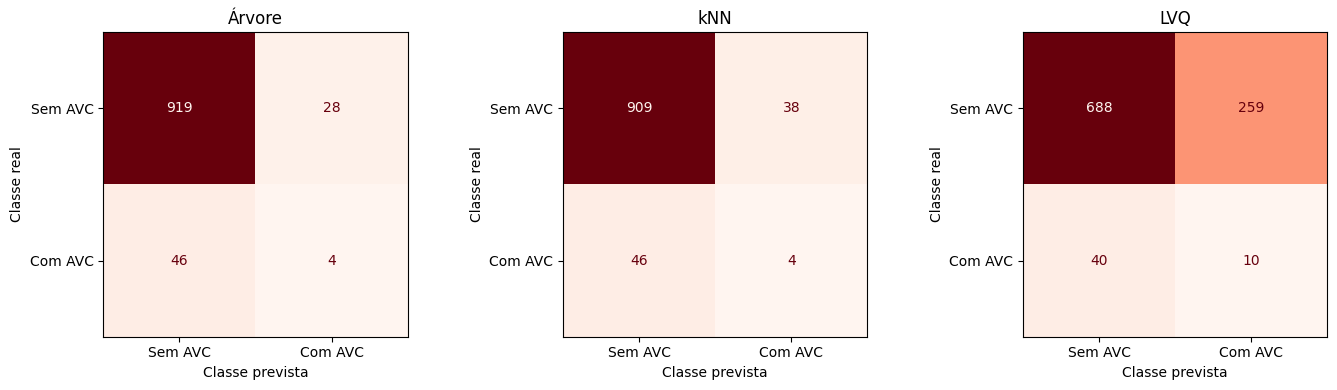

In [ ]:
# Cria os gráficos
fig, eixos = plt.subplots(
    1,
    3,
    figsize=(14, 4),
)

# Percorre os modelos
for eixo, (
    nome,
    previsao,
) in zip(
    eixos,
    predicoes_teste.items(),
):
    # Calcula matriz
    matriz = confusion_matrix(
        y_te_a,
        previsao,
        labels=[0, 1],
    )

    # Prepara exibição
    exibicao = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=[
            "Sem AVC",
            "Com AVC",
        ],
    )

    # Desenha matriz
    exibicao.plot(
        ax=eixo,
        cmap="Reds",
        colorbar=False,
    )

    # Identifica modelo
    eixo.set_title(
        nome
    )

    eixo.set_xlabel(
        "Classe prevista"
    )

    eixo.set_ylabel(
        "Classe real"
    )

plt.tight_layout()
plt.show()

##Seção 5.3 — Comparação e diagnóstico final

In [ ]:
# Guarda os resultados
linhas_desempenho = []

# Percorre os modelos
for nome in predicoes_teste:
    linhas_desempenho.append({
        "modelo": nome,

        "treino": balanced_accuracy_score(
            y_tr_a,
            predicoes_treino[nome],
        ),

        "validação": balanced_accuracy_score(
            y_va_a,
            predicoes_validacao[nome],
        ),

        "teste": resultados_teste.loc[
            nome,
            "acurácia_balanceada",
        ],
    })

# Cria tabela
comparacao = pd.DataFrame(
    linhas_desempenho
).set_index(
    "modelo"
)

# Calcula diferença principal
comparacao["gap_treino_validação"] = (
    comparacao["treino"]
    - comparacao["validação"]
)

# Calcula estabilidade final
comparacao["gap_validação_teste"] = (
    comparacao["validação"]
    - comparacao["teste"]
)

# Exibe comparação
display(
    comparacao.round(3)
)

,treino,validação,teste,gap_treino_validação,gap_validação_teste
modelo,,,,,
Árvore,0.746,0.543,0.525,0.203,0.018
kNN,1.000,0.522,0.520,0.478,0.002
LVQ,0.551,0.562,0.463,-0.011,0.098


## Seção 6 — Declaração de uso de IA

**Ferramentas utilizadas:** ChatGPT (OpenAI).

**Finalidades do uso:**

- revisão da estrutura do notebook em relação à especificação da entrega;
- identificação de erros nas implementações iniciais de árvore e kNN;
- sugestão da organização das buscas de hiperparâmetros, métricas e gráficos;
- apoio à redação dos comentários do código